In [45]:
import glob  as g
import matplotlib.pyplot as plt
import pandas as pd

In [63]:
files =sorted(g.glob('../data/raw/*.csv'))
demand=pd.concat([pd.read_csv(file) for file in files], ignore_index=True)
print(demand)



       REGION       SETTLEMENTDATE  TOTALDEMAND    RRP PERIODTYPE
0        NSW1  2024/01/01 00:05:00      6574.92  57.98      TRADE
1        NSW1  2024/01/01 00:10:00      6651.09  70.27      TRADE
2        NSW1  2024/01/01 00:15:00      6538.96  57.98      TRADE
3        NSW1  2024/01/01 00:20:00      6497.99  54.95      TRADE
4        NSW1  2024/01/01 00:25:00      6404.55  54.95      TRADE
...       ...                  ...          ...    ...        ...
210523   NSW1  2025/12/31 23:40:00      6815.60  58.19      TRADE
210524   NSW1  2025/12/31 23:45:00      6747.40  68.25      TRADE
210525   NSW1  2025/12/31 23:50:00      6787.87  77.33      TRADE
210526   NSW1  2025/12/31 23:55:00      6751.40  67.93      TRADE
210527   NSW1  2026/01/01 00:00:00      6777.74  77.89      TRADE

[210528 rows x 5 columns]


In [85]:

demand["SETTLEMENTDATE"] = pd.to_datetime(demand["SETTLEMENTDATE"])
demand = demand[["SETTLEMENTDATE", "TOTALDEMAND"]]
demand.head()


,SETTLEMENTDATE,TOTALDEMAND
0,2024-01-01 00:05:00,6574.92
1,2024-01-01 00:10:00,6651.09
2,2024-01-01 00:15:00,6538.96
3,2024-01-01 00:20:00,6497.99
4,2024-01-01 00:25:00,6404.55


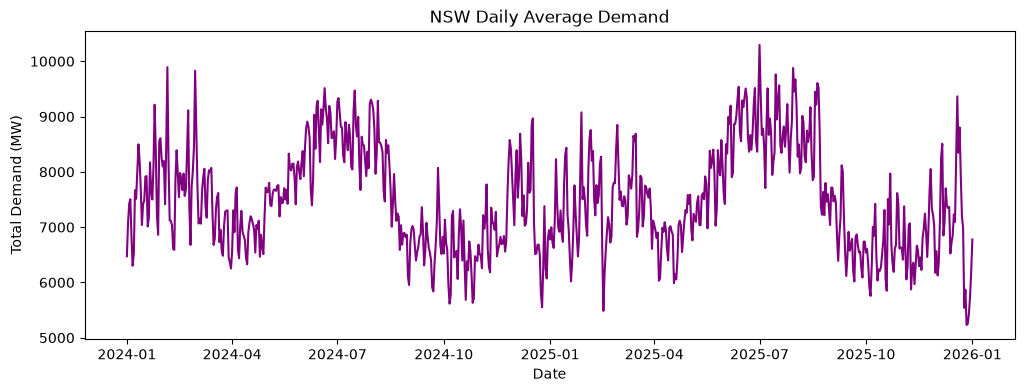

In [ ]:
daily = demand.set_index("SETTLEMENTDATE").resample("D").mean()
x = daily.index
y = daily["TOTALDEMAND"]
plt.figure(figsize=(12, 4))
plt.plot(x, y, color="purple")
plt.title("NSW Daily Average Demand")
plt.xlabel("Date")
plt.ylabel("Total Demand (MW)")
plt.show()
